# PR11: Advanced Machine Learning and Model Optimization

**Aim:** Compare SVM, Random Forest and AdaBoost on the Car Evaluation dataset. Use five-fold cross-validation and GridSearchCV, then compare performance before and after tuning.

Keep `car_evaluation.csv` in the same folder as this notebook before running it. The CSV has no header: all 1,728 rows are data. Six categorical inputs predict one of four classes: `unacc` (unacceptable), `acc` (acceptable), `good`, or `vgood` (very good).

Every model uses the same training/test split and validation folds. One-hot encoding is fitted inside each pipeline. The test set is excluded from parameter selection.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## 2. Load and inspect the dataset
The CSV contains six categorical features and one class label, without a header row. There are no missing values in the supplied file, so diabetes-specific zero replacement and median imputation are removed.

In [2]:
names = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df = pd.read_csv("car_evaluation.csv", header=None, names=names)

print("Samples:", df.shape[0])
print("Input features:", df.shape[1] - 1)
print("\nFirst five rows:")
print(df.head().to_string(index=False))
print("\nMissing values:")
print(df.isna().sum())
print("\nClass counts:")
print(df["class"].value_counts())

Samples: 1728
Input features: 6

First five rows:
buying maint doors persons lug_boot safety class
 vhigh vhigh     2       2    small    low unacc
 vhigh vhigh     2       2    small    med unacc
 vhigh vhigh     2       2    small   high unacc
 vhigh vhigh     2       2      med    low unacc
 vhigh vhigh     2       2      med    med unacc

Missing values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Class counts:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


## 3. Split the data
Use 80% for training and 20% for testing. Stratification preserves approximately the same proportions of all four classes. The target stays as text labels; the classifiers can learn these labels directly.

In [3]:
X = df.drop(columns="class")
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1382
Testing samples: 346


## 4. Define the three models separately
One-hot encoding converts categories such as `low`, `med`, and `high` into numeric indicator columns. Each pipeline learns its categories only from its training data. `handle_unknown="ignore"` allows prediction when an input contains an unseen category. All encoded columns are 0/1, so an additional StandardScaler is omitted. Dense output works with all three classifiers.

In [4]:
# Model 1: Support Vector Machine
svm = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("model", SVC())
])

In [5]:
# Model 2: Random Forest
rf = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("model", RandomForestClassifier(random_state=42))
])

In [6]:
# Model 3: AdaBoost
ada = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("model", AdaBoostClassifier(random_state=42))
])

models = {"SVM": svm, "Random Forest": rf, "AdaBoost": ada}

## 5. Evaluate before optimization and perform cross-validation
Train the default models and calculate test accuracy, precision, recall and F1. Precision, recall and F1 use `average="weighted"`: compute each class's metric and average according to the number of true examples in that class. This supports four classes and accounts for their unequal counts, but common classes influence the score more. Weighted recall equals accuracy in this single-label task. Five-fold cross-validation uses only training records.

In [7]:
def evaluate(model):
    predictions = model.predict(X_test)
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1": f1_score(y_test, predictions, average="weighted", zero_division=0)
    }


before = {}
cv_before = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    before[name] = evaluate(model)

    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_before[name] = scores.mean()
    print("\n" + name)
    print("Fold accuracies:", scores.round(4))
    print("Mean CV accuracy:", round(scores.mean(), 4))
    print("CV standard deviation:", round(scores.std(), 4))

before_df = pd.DataFrame(before).T
print("\nTest performance BEFORE optimization:")
print(before_df.round(4).to_string())


SVM
Fold accuracies: [0.9675 0.9711 0.9674 0.9565 0.9638]
Mean CV accuracy: 0.9653
CV standard deviation: 0.005

Random Forest
Fold accuracies: [0.9422 0.9675 0.9565 0.9457 0.9457]
Mean CV accuracy: 0.9515
CV standard deviation: 0.0093

AdaBoost
Fold accuracies: [0.8375 0.8628 0.8225 0.8406 0.8333]
Mean CV accuracy: 0.8393
CV standard deviation: 0.0132

Test performance BEFORE optimization:
               Accuracy  Precision  Recall      F1
SVM              0.9740     0.9752  0.9740  0.9742
Random Forest    0.9682     0.9688  0.9682  0.9678
AdaBoost         0.8439     0.8554  0.8439  0.8394


## 6. Hyperparameter tuning using Grid Search
Each grid contains multiple parameter combinations. `model__` refers to the classifier step inside the pipeline. SVM gamma is searched only with the RBF kernel because a linear kernel does not use it.


In [8]:
param_grids = {
    "SVM": [
        {"model__kernel": ["linear"], "model__C": [0.1, 1, 10]},
        {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10],
         "model__gamma": ["scale", 0.01, 0.1]}
    ],
    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5]
    },
    "AdaBoost": {
        "model__n_estimators": [50, 100],
        "model__learning_rate": [0.1, 0.5, 1.0]
    }
}

optimized_models = {}
cv_after = {}

for name, model in models.items():
    grid = GridSearchCV(
        model,
        param_grids[name],
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )
    grid.fit(X_train, y_train)
    optimized_models[name] = grid.best_estimator_
    cv_after[name] = grid.best_score_

    print("\n" + name)
    print("Best parameters:", grid.best_params_)
    print("Best CV accuracy:", round(grid.best_score_, 4))



SVM
Best parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV accuracy: 0.9971

Random Forest
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV accuracy: 0.9515

AdaBoost
Best parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 100}
Best CV accuracy: 0.8654


## 7. Evaluate after optimization
Evaluate the best models on exactly the same held-out test samples.

In [9]:
after = {}
for name, model in optimized_models.items():
    after[name] = evaluate(model)

after_df = pd.DataFrame(after).T
print("Test performance AFTER optimization:")
print(after_df.round(4).to_string())


Test performance AFTER optimization:
               Accuracy  Precision  Recall      F1
SVM              1.0000     1.0000  1.0000  1.0000
Random Forest    0.9682     0.9688  0.9682  0.9678
AdaBoost         0.8584     0.8894  0.8584  0.8525


## 8. Compare before and after optimization
All scores below range from 0 to 1. The best grid-search CV score was used to select parameters, so it is a selection score rather than an independent estimate. Compare held-out test scores to assess the final models.


               Accuracy Before  Precision Before  Recall Before  F1 Before  Accuracy After  Precision After  Recall After  F1 After  CV Accuracy Before  Best Search CV Accuracy  Test Accuracy Change
Model                                                                                                                                                                                                 
SVM                     0.9740            0.9752         0.9740     0.9742          1.0000           1.0000        1.0000    1.0000              0.9653                   0.9971                0.0260
Random Forest           0.9682            0.9688         0.9682     0.9678          0.9682           0.9688        0.9682    0.9678              0.9515                   0.9515                0.0000
AdaBoost                0.8439            0.8554         0.8439     0.8394          0.8584           0.8894        0.8584    0.8525              0.8393                   0.8654                0.0145

High

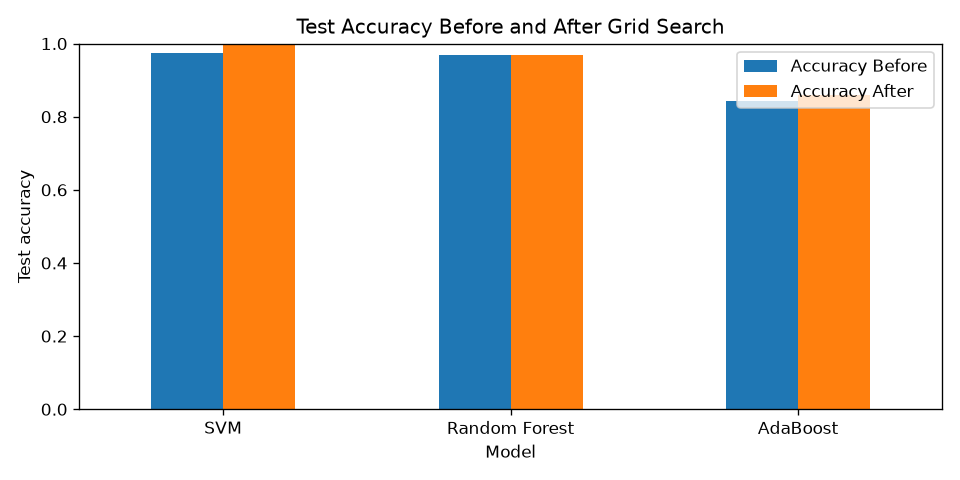

In [10]:
comparison = before_df.add_suffix(" Before").join(after_df.add_suffix(" After"))
comparison["CV Accuracy Before"] = pd.Series(cv_before)
comparison["Best Search CV Accuracy"] = pd.Series(cv_after)
comparison["Test Accuracy Change"] = comparison["Accuracy After"] - comparison["Accuracy Before"]
comparison.index.name = "Model"

print(comparison.round(4).to_string())

comparison[["Accuracy Before", "Accuracy After"]].plot.bar(
    figsize=(8, 4), rot=0
)
plt.ylabel("Test accuracy")
plt.title("Test Accuracy Before and After Grid Search")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("\nHighest tuned test accuracy in this split:", after_df["Accuracy"].idxmax())
print("Tuning selects the best CV parameters; test accuracy may increase, stay the same or decrease.")


## Conclusion
SVM, Random Forest and AdaBoost were compared on the Car Evaluation dataset using the same split and folds. Pipelines converted categorical features into numeric indicator columns. Five-fold GridSearchCV selected settings using training-data accuracy. Held-out accuracy and weighted precision, recall and F1 were compared before and after tuning. Tuning does not guarantee improved test performance.

## Viva points
- **Input:** Six categorical features; **target:** four car evaluation classes.
- **One-hot encoding:** Convert each category into numeric 0/1 columns without assigning an artificial numerical distance between categories.
- **Weighted metrics:** Average per-class scores using each class's true sample count.
- **Cross-validation:** Train on four folds, validate on the fifth, and repeat.
- **Grid Search:** Select the searched parameter combination with the highest mean validation accuracy.
- **Pipeline:** Fit encoding inside each training fold to avoid preprocessing leakage.
- **Test set:** Excluded from tuning; used for the before/after evaluation.